# Análisis estadístico de tarifas telefónicas

**Luis Eduardo Aguilar Castellanos** · TripleTen · Sprint 5

Comparé los planes Surf y Ultimate de Megaline para entender cómo cambia el consumo y cuánto ingreso mensual genera cada plan. Integré los datos de usuarios, llamadas, mensajes e internet y apliqué las reglas de facturación de la compañía.

## Plan de acción

Primero revisé la estructura de los cinco archivos y sus fechas. Después agrupé el consumo por usuario y mes, calculé los cargos por excedentes y comparé ambos planes con gráficos y pruebas estadísticas. El objetivo es analizar ingresos, no rentabilidad: no cuento con información de costos.

## Inicialización

In [1]:
# Cargar todas las librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st
import numpy as np
from math import factorial


## Cargar datos

In [2]:
from pathlib import Path
import os
DATA = Path(os.environ.get('MEGALINE_DATA_DIR', str(Path.cwd() / 'data')))
files = ['plans','users','messages','calls','internet']
missing = [f'megaline_{name}.csv' for name in files if not (DATA / f'megaline_{name}.csv').is_file()]
if missing: raise FileNotFoundError('Faltan archivos en MEGALINE_DATA_DIR: ' + ', '.join(missing))
plans, users, messages, calls, internet = [pd.read_csv(DATA / f'megaline_{name}.csv') for name in files]
# Los nombres no son necesarios para analizar consumo e ingresos.
users[['first_name','last_name']] = '[omitido]'


## Preparar los datos

**Exploración de datos**

Comenzaremos por descubrir la estructura inicial de los datos. Esto incluye la revisión de:

Separadores: Verificar que los archivos se lean correctamente.

Nombres de columnas: Identificar el uso de mayúsculas innecesarias o la falta de formato snake_case.

Claridad: Corregir nombres poco claros o ambiguos.

Limpieza de cadenas: Detectar y eliminar espacios extra en los registros o encabezados.

## Tarifas

In [3]:
# Imprime la información general/resumida sobre el DataFrame de las tarifas

plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 256.0+ bytes


In [4]:
# Imprime una muestra de los datos para las tarifas
display(plans.head()) # Se usa el metodo "head()" ya que detectamos gracias a Info que solo tenemos 2 filas por lo que "sample()" no seria relevante en este caso.


,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


El dataset tiene una estructura de 8 columnas con 2 filas.

En general describe como se conforma cada paquete en los que estamos interesados, como:

- Limite de mensajes
- Limite de mb por mes
- Minutos para llamadas
- Costo de cada paquete
- Costos al exceder el limite del plan para cada rubro.
- Nombre del plan

No se observan datos ausentes ni nulos

Las columnas de mb_per_month_included es algo engañosa, ya que muestra el total de mb incluidos pero el cobro extra se hace por GB y realizar calculos posteriores con esta columna seria problematico ya que elevaria las cifras artificialmente.

Crearemos una columna nueva con estos valores pero convertidos a gb para que sea consistente con el cobro extra de gb consumido si se excede el plan, pero manteniendo la columna original para no perder la referencia inicial.


## Corregir datos

In [5]:
plans['gb_per_month'] = np.ceil(plans['mb_per_month_included'] / 1024).astype(int)

display(plans)

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month
0,50,15360,500,20,10,0.03,0.03,surf,15
1,1000,30720,3000,70,7,0.01,0.01,ultimate,30


## Enriquecer los datos

In [6]:
#crearemos una segunda columna en este dataset en el cual delimitaremos el costo tambien por mb extra dividiendo el precio por gb extra entre 1024 para tener este valor disponible tambien de manera informativa.

plans['usd_per_mb'] = plans['usd_per_gb']/1024

display(plans)


,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month,usd_per_mb
0,50,15360,500,20,10,0.03,0.03,surf,15,0.009766
1,1000,30720,3000,70,7,0.01,0.01,ultimate,30,0.006836


## Usuarios/as

In [7]:
# Imprime la información general/resumida sobre el DataFrame de usuarios

users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB


In [8]:
# Imprime una muestra de datos para usuarios
display(users.sample(10,random_state=45))

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
204,1204,[omitido],[omitido],44,"Chicago-Naperville-Elgin, IL-IN-WI MSA",2018-08-20,ultimate,NaN
481,1481,[omitido],[omitido],32,"Urban Honolulu, HI MSA",2018-12-27,surf,NaN
296,1296,[omitido],[omitido],36,"Miami-Fort Lauderdale-West Palm Beach, FL MSA",2018-10-20,ultimate,2018-12-18
38,1038,[omitido],[omitido],32,"Nashville-Davidson–Murfreesboro–Franklin, TN MSA",2018-06-25,ultimate,NaN
298,1298,[omitido],[omitido],53,"Nashville-Davidson–Murfreesboro–Franklin, TN MSA",2018-09-21,surf,2018-12-19
61,1061,[omitido],[omitido],38,"Columbia, SC MSA",2018-03-08,ultimate,NaN
371,1371,[omitido],[omitido],27,"Portland-Vancouver-Hillsboro, OR-WA MSA",2018-10-27,surf,NaN
360,1360,[omitido],[omitido],75,"Charlotte-Concord-Gastonia, NC-SC MSA",2018-09-20,surf,NaN
413,1413,[omitido],[omitido],38,"Bakersfield, CA MSA",2018-07-12,surf,NaN
64,1064,[omitido],[omitido],46,"New York-Newark-Jersey City, NY-NJ-PA MSA",2018-06-03,surf,NaN



**Análisis de la estructura del Dataset**

El dataset cuenta con una estructura de 8 columnas y 500 filas:

`reg_date`: Tiene un formato de `object` en lugar de `datetime`. Se debe establecer el formato de fecha `AAAA-MM-DD` para permitir agrupaciones correctas en análisis futuros.

`churn_date`: Según la documentación, si el valor es ausente, el servicio seguía activo al momento de extraer los datos. Si contiene una fecha (que actualmente es de tipo `object`), indica que el usuario ha cancelado el servicio. La columna presenta 34 datos no nulos, lo que significa que 34 usuarios de esta muestra ya habían cancelado o suspendido su suscripción.

Correcciones técnicas:
Procederemos a transformar las columnas `'churn_date'` y `'reg_date'` utilizando el método `to_datetime()` para establecer el formato de fecha correcto.


### Corregir los datos

In [9]:
#verificaremos primero si el Dataframe tiene Filas Duplicadas con la siguiente linea:
users_duplicates = users.duplicated().sum()

print(f"El Dataframe 'users' contiene {users_duplicates} duplicados.")


El Dataframe 'users' contiene 0 duplicados.


In [10]:
# Despues de verificar si existen duplicados se procede a la correccion de las fechas a formato de fecha correcto.
users['reg_date'] = pd.to_datetime(users['reg_date'], format='%Y-%m-%d')
users['churn_date']= pd.to_datetime(users['churn_date'], format='%Y-%m-%d')
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   first_name  500 non-null    object        
 2   last_name   500 non-null    object        
 3   age         500 non-null    int64         
 4   city        500 non-null    object        
 5   reg_date    500 non-null    datetime64[ns]
 6   plan        500 non-null    object        
 7   churn_date  34 non-null     datetime64[ns]
dtypes: datetime64[ns](2), int64(2), object(4)
memory usage: 31.4+ KB


Despues de ejecutar estas lineas confirmamos que las fechas se corrigieron satisfactoriamente y ahora son tipo `datetime64`

In [11]:
display(users.sample(10,random_state=45))

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
204,1204,[omitido],[omitido],44,"Chicago-Naperville-Elgin, IL-IN-WI MSA",2018-08-20,ultimate,NaT
481,1481,[omitido],[omitido],32,"Urban Honolulu, HI MSA",2018-12-27,surf,NaT
296,1296,[omitido],[omitido],36,"Miami-Fort Lauderdale-West Palm Beach, FL MSA",2018-10-20,ultimate,2018-12-18
38,1038,[omitido],[omitido],32,"Nashville-Davidson–Murfreesboro–Franklin, TN MSA",2018-06-25,ultimate,NaT
298,1298,[omitido],[omitido],53,"Nashville-Davidson–Murfreesboro–Franklin, TN MSA",2018-09-21,surf,2018-12-19
61,1061,[omitido],[omitido],38,"Columbia, SC MSA",2018-03-08,ultimate,NaT
371,1371,[omitido],[omitido],27,"Portland-Vancouver-Hillsboro, OR-WA MSA",2018-10-27,surf,NaT
360,1360,[omitido],[omitido],75,"Charlotte-Concord-Gastonia, NC-SC MSA",2018-09-20,surf,NaT
413,1413,[omitido],[omitido],38,"Bakersfield, CA MSA",2018-07-12,surf,NaT
64,1064,[omitido],[omitido],46,"New York-Newark-Jersey City, NY-NJ-PA MSA",2018-06-03,surf,NaT


### Enriquecer los datos

Crearemos tres columnas nuevas para facilitar el filtrado de datos. Estas se generarán extrayendo información de las columnas originales, las cuales mantendremos intactas para no alterar la estructura inicial del dataset:

Columna `state`: Extraeremos el estado del usuario para permitir un análisis regional mediante filtros posteriores.

Columna de actividad: Clasificaremos a los usuarios de la columna `churn_dat`e. Asignaremos `1` a los usuarios con valores ausentes (quienes continúan activos) y `0` a los usuarios con valores no nulos (aquellos que ya cancelaron su servicio).

Columna `month`: Extraeremos el mes de la fecha de registro en `reg_date` para facilitar el filtrado y la agrupación de usuarios por periodos mensuales.



In [12]:
#Se crea la serie booleana de usuarios activos: 1 = Activos, 0 = Inactivos
users['is_active'] = users['churn_date'].isna().astype('int')
print(users['is_active'].value_counts())
print()
users_state = users['city'].str.split(',').str[1]

users['state'] = users_state.str.replace('MSA','',regex=False).str.strip()

print(users['state'].value_counts())

display(users[['city','state']].sample(10))

1    466
0     34
Name: is_active, dtype: int64

NY-NJ-PA       80
CA             78
TX             39
FL             25
IL-IN-WI       19
PA-NJ-DE-MD    17
MI             16
GA             14
WA             13
TN             12
MA-NH          12
AZ             11
DC-VA-MD-WV    11
MN-WI          11
LA              9
OH              9
CO              9
NC-SC           8
OH-KY-IN        8
OR-WA           8
NV              7
SC              7
IN              6
OK              6
CT              6
NY              6
PA              5
HI              5
KY-IN           5
VA              4
MD              4
AL              4
VA-NC           4
MO-IL           3
WI              3
RI-MA           3
UT              3
NE-IA           2
TN-MS-AR        2
MO-KS           2
NC              2
NM              2
Name: state, dtype: int64


,city,state
255,"Oklahoma City, OK MSA",OK
346,"Tucson, AZ MSA",AZ
465,"Pittsburgh, PA MSA",PA
413,"Bakersfield, CA MSA",CA
246,"Tampa-St. Petersburg-Clearwater, FL MSA",FL
395,"New York-Newark-Jersey City, NY-NJ-PA MSA",NY-NJ-PA
431,"Sacramento–Roseville–Folsom, CA MSA",CA
451,"Charlotte-Concord-Gastonia, NC-SC MSA",NC-SC
141,"New York-Newark-Jersey City, NY-NJ-PA MSA",NY-NJ-PA
262,"Dallas-Fort Worth-Arlington, TX MSA",TX


In [13]:
# Se crea la columna 'reg_month' para la revision de la cantidad de registros por mes esto nos dara mas flexibilidad a ala hora de analizar a mas profundidad los datos por mes y la logevidad de los usuarios.

users['month'] = users['reg_date'].dt.month

reg_per_month = users['month'].value_counts().sort_index()

print("Cantidad de Registros Por Mes")
print(reg_per_month)

Cantidad de Registros Por Mes
1     49
2     42
3     40
4     45
5     38
6     54
7     36
8     47
9     32
10    42
11    38
12    37
Name: month, dtype: int64


In [14]:
#verificamos Todas las columnas creadas

display(users.sample(5,random_state=34))

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,is_active,state,month
163,1163,[omitido],[omitido],27,"Los Angeles-Long Beach-Anaheim, CA MSA",2018-01-12,ultimate,NaT,1,CA,1
183,1183,[omitido],[omitido],71,"Chicago-Naperville-Elgin, IL-IN-WI MSA",2018-07-20,surf,NaT,1,IL-IN-WI,7
286,1286,[omitido],[omitido],52,"New Haven-Milford, CT MSA",2018-12-07,surf,NaT,1,CT,12
105,1105,[omitido],[omitido],57,"Providence-Warwick, RI-MA MSA",2018-01-08,surf,NaT,1,RI-MA,1
436,1436,[omitido],[omitido],69,"Philadelphia-Camden-Wilmington, PA-NJ-DE-MD MSA",2018-08-26,ultimate,NaT,1,PA-NJ-DE-MD,8


## Llamadas

In [15]:
# Imprime la información general/resumida sobre el DataFrame de las llamadas

calls.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB


Revisé los tipos de datos y los valores ausentes de las llamadas.

In [16]:
# Imprime una muestra de datos para las llamadas

calls_na = calls.isna().sum()
calls_duplicated = calls.duplicated().sum()

print(f"El numero de valores ausentes es de:")
print(calls_na)
print(f"El numero de registros duplicados es de: {calls_duplicated}")
print()
display(calls.sample(5,random_state=25))

El numero de valores ausentes es de:
id           0
user_id      0
call_date    0
duration     0
dtype: int64
El numero de registros duplicados es de: 0



,id,user_id,call_date,duration
59445,1214_514,1214,2018-04-12,1.87
34514,1130_34,1130,2018-11-12,0.00
54329,1196_212,1196,2018-10-31,9.29
132025,1475_172,1475,2018-09-10,0.00
16217,1064_75,1064,2018-10-27,2.79



**Análisis de la estructura del Dataset de llamadas**

El dataset cuenta con una estructura de 4 columnas y 137735 filas de registro.

Formato de fechas: A primera vista, se observa que la columna `call_date` no tiene el formato de fecha adecuado. Se debe corregir para permitir el filtrado temporal y detectar patrones de consumo.

Valores ausentes: Aparentemente no se observan datos ausentes; sin embargo, ejecutaremos `isna().sum()` para verificarlo con precisión.

Duplicados: Comprobaremos la existencia de registros duplicados utilizando directamente el método `duplicated()` sobre el DataFrame.

Redondeo de consumo: Según la documentación, la compañía redondea hacia arriba las fracciones de minuto (por ejemplo, `1.49` pasa a `2`). Crearemos una columna nueva para estos valores redondeados, manteniendo la original intacta por referencia. Para esto, utilizaremos la función `ceil()`, cumpliendo así con las políticas de facturación de la compañía.

Llamadas de duración `0.0`: Identificamos un volumen considerable de llamadas con duración de `0.0`. Esto podría indicar llamadas no contestadas o perdidas; por lo tanto, las aislaremos en una variable diferente para mantenerlas bajo observación sin que afecten los cálculos de consumo promedio.


### Corregir los datos

In [17]:
# Realizamos el cambio de formato de tipo objet en la columna "call_date" para que sea un formato de fecha correcto.

calls['call_date'] = pd.to_datetime(calls['call_date'],format=  '%Y-%m-%d')

calls.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         137735 non-null  object        
 1   user_id    137735 non-null  int64         
 2   call_date  137735 non-null  datetime64[ns]
 3   duration   137735 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 4.2+ MB


### Enriquecer los datos

Se creará una columna `call_month` en la cual extraeremos el mes de las llamadas realizadas. Esto nos permitirá filtrar a través del tiempo para establecer patrones en las llamadas de una manera eficaz.


In [18]:
calls['month'] = calls['call_date'].dt.month

calls_per_month = calls['month'].value_counts().sort_index()

print("Cantidad de llamadas Por Mes")
print(calls_per_month)

Cantidad de llamadas Por Mes
1       172
2       774
3      1620
4      3442
5      5959
6      8221
7     11105
8     13590
9     16523
10    21064
11    24651
12    30614
Name: month, dtype: int64


Observacion:

Se observa un Claro incremento de llamadas a mediados del año, ¿Tendra que ver con las Fechas de Registro de los usuarios?.

In [19]:
# Redondeamos las llamadas de la columna original "duration" al entero siguiente para cumplir con la politica de la compañia.

calls['calls_duration_mins'] = np.ceil(calls['duration']).astype(int)

# Extraemos las llamadas con duracion 0 para almacenarlas en una variable independiente y poder determinar el porcentaje de estas llamadas dentro del Dataframe original.

zero_calls_duration = calls[calls['duration'] == 0]

print(f"Porcentaje de llamadas con duración cero: {len(zero_calls_duration) / len(calls):.2%}")

display(calls.sample(10,random_state=15))

Porcentaje de llamadas con duración cero: 19.48%


,id,user_id,call_date,duration,month,calls_duration_mins
26617,1100_174,1100,2018-11-28,7.66,11,8
88146,1324_192,1324,2018-12-15,8.04,12,9
62381,1223_567,1223,2018-07-16,5.59,7,6
77619,1277_695,1277,2018-07-21,10.19,7,11
62892,1226_291,1226,2018-12-10,14.57,12,15
55981,1201_79,1201,2018-08-09,5.73,8,6
99926,1358_323,1358,2018-10-30,5.43,10,6
48990,1176_89,1176,2018-10-25,14.15,10,15
32883,1123_241,1123,2018-11-13,9.49,11,10
107688,1382_419,1382,2018-10-24,0.00,10,0


El 19.48 % de las llamadas registra duración cero. Este dato, por sí solo, no permite determinar la causa.

## Mensajes

In [20]:
# Imprime la información general/resumida sobre el DataFrame de los mensajes

print("El número de valores ausentes es:")
print(messages.isna().sum())
print()
print(f"El número de registros duplicados es de: {messages.duplicated().sum()}")

messages.info()


El número de valores ausentes es:
id              0
user_id         0
message_date    0
dtype: int64

El número de registros duplicados es de: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB


Revisé los valores ausentes, duplicados y una muestra de mensajes.

In [21]:
# Imprime una muestra de datos para los mensajes

display(messages.sample(10,random_state=16))

,id,user_id,message_date
12284,1081_23,1081,2018-06-07
52743,1336_778,1336,2018-04-23
54357,1343_457,1343,2018-12-13
41729,1268_102,1268,2018-10-08
18582,1120_429,1120,2018-05-23
12623,1082_174,1082,2018-11-28
50790,1330_425,1330,2018-12-19
63198,1401_157,1401,2018-10-26
2314,1028_223,1028,2018-12-27
4813,1045_15,1045,2018-11-01



En este dataset no se observan valores nulos ni registros duplicados.

Formato de fechas: Al igual que en los datasets anteriores, la columna de fecha no cuenta con el formato correcto. Realizaremos la conversión necesaria para estandarizar los datos.

Agrupación temporal: Crearemos la columna message_month a partir de la fecha de envío. Esto nos permitirá filtrar los mensajes y agruparlos por mes para facilitar el análisis de patrones de uso.


### Corregir los datos

Corregiremos los formatos de fecha, tal como realizamos anteriormente, utilizando el método `to_datetime()` para establecer el valor adecuado para el análisis posterior.

In [22]:
messages['message_date'] = pd.to_datetime(messages['message_date'], format='%Y-%m-%d')

messages.info()
display(messages.sample(5,random_state=18))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  object        
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.7+ MB


,id,user_id,message_date
18906,1122_135,1122,2018-05-27
72658,1470_286,1470,2018-08-08
9446,1069_472,1069,2018-11-12
24741,1146_494,1146,2018-12-19
68742,1444_225,1444,2018-09-05


Se corrige satisfactoriamente el formato de la fecha en el Dataframe.

### Enriquecer los datos

Crearemos la Columna de mensajes mensuales que nos ayudara en analisis posteriores extrayendo el mes.


In [23]:
messages['month'] = messages['message_date'].dt.month

display(messages.sample(5,random_state=18))

,id,user_id,message_date,month
18906,1122_135,1122,2018-05-27,5
72658,1470_286,1470,2018-08-08,8
9446,1069_472,1069,2018-11-12,11
24741,1146_494,1146,2018-12-19,12
68742,1444_225,1444,2018-09-05,9


## Internet

In [24]:
# Imprime la información general/resumida sobre el DataFrame de internet
print("EL numero de valores nulos es:")
print(internet.isna().sum())
print()
print(f"El número de Valores Duplicados es de: {internet.duplicated().sum()}")
print()
internet.info()

EL numero de valores nulos es:
id              0
user_id         0
session_date    0
mb_used         0
dtype: int64



El número de Valores Duplicados es de: 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB


In [25]:
# Imprime una muestra de datos para el tráfico de internet

display(internet.sample(10,random_state=38))


,id,user_id,session_date,mb_used
42912,1191_91,1191,2018-05-04,857.18
35279,1159_116,1159,2018-11-24,709.86
55132,1249_415,1249,2018-06-20,291.43
74965,1353_128,1353,2018-06-28,104.58
39803,1179_134,1179,2018-12-27,158.57
55722,1252_134,1252,2018-08-27,525.67
37540,1170_339,1170,2018-11-09,0.00
16462,1073_401,1073,2018-09-04,221.43
9209,1047_47,1047,2018-12-26,407.50
192,1001_345,1001,2018-08-18,249.51



Análisis del dataset de internet

No se observan valores nulos, ausentes ni registros duplicados en este dataset.

Formato de fechas: La columna de fecha se encuentra en formato `object`, al igual que en los demás DataFrames. Utilizaremos el mismo método, `to_datetime()`, para convertirla al formato correcto.

Política de redondeo: Según la documentación, las sesiones individuales no se redondean. Por lo tanto, pospondremos la agrupación para un paso posterior y mantendremos la información de los `mb` tal como se encuentra originalmente.

Gestión de sesiones en `0.0`: Crearemos una columna para identificar las sesiones con valor de `0.0`. Esto nos permitirá realizar consultas específicas posteriormente sin necesidad de eliminar esta información por el momento.



### Corregir los datos

Al igual que en los datasets anteriores, convertiremos las fechas en formato correcto con el mismo metodo para poder realizar el filtro en el siquiente paso.

In [26]:
# Convertimos la Fecha Satisfactoriamente al formato correcto.

internet['session_date'] = pd.to_datetime(internet['session_date'],format='%Y-%m-%d')

sessions_empty = internet[internet['mb_used'] == 0]

display(internet.sample(5,random_state=25))
print()
# Mostramos la información nuevamente del DF para verificar el cambio de tipo object a datetime64
internet.info()

,id,user_id,session_date,mb_used
4706,1028_265,1028,2018-09-19,205.11
39181,1176_2,1176,2018-12-10,165.55
74526,1351_12,1351,2018-12-20,132.41
54938,1249_131,1249,2018-08-22,504.56
7667,1041_507,1041,2018-10-05,0.00



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  object        
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[ns]
 3   mb_used       104825 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 3.2+ MB


### Enriquecer los datos

Crearemos una columna `month` para facilitar la agrupación mensual. Esto nos permitirá sumar las sesiones de los usuarios, calcular el total de `mb` consumidos y determinar el consumo final en `gb` por cada mes.


In [27]:
internet['month'] = internet['session_date'].dt.month

sessions_empty = internet[internet['mb_used'] == 0]
print(f"Sesiones con 0 mb: {len(sessions_empty)} ")
print()
print(f"Total de Sesiones del DF: {len(internet)}")
print()
print(f"Porcentaje de sesiones con 0 mb: {len(sessions_empty)/len(internet):.2%} ")

Sesiones con 0 mb: 13747 

Total de Sesiones del DF: 104825

Porcentaje de sesiones con 0 mb: 13.11% 


## Estudiar las condiciones de las tarifas

Imprimiremos nuevamente los datos de las tarifas de cada plan para sus respectivos consumos. Esto nos permitirá realizar las operaciones exactas de acuerdo con la política de facturación de la compañía para el cálculo del cobro mensual.

In [28]:
# Imprime las condiciones de la tarifa y asegúrate de que te quedan claras

display(plans)

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month,usd_per_mb
0,50,15360,500,20,10,0.03,0.03,surf,15,0.009766
1,1000,30720,3000,70,7,0.01,0.01,ultimate,30,0.006836


## Agregar datos por usuario


In [29]:
calls.columns

Index(['id', 'user_id', 'call_date', 'duration', 'month',
       'calls_duration_mins'],
      dtype='object')

In [30]:
# Calcula el número de llamadas hechas por cada usuario al mes. Guarda el resultado.

calls_per_month = calls.groupby(['user_id', 'month'])['id'].count().reset_index()

In [31]:
display(calls_per_month.head())

,user_id,month,id
0,1000,12,16
1,1001,8,27
2,1001,9,49
3,1001,10,65
4,1001,11,64


In [32]:
calls_per_month.columns = ['user_id','month','calls_made']

display(calls_per_month.head())

,user_id,month,calls_made
0,1000,12,16
1,1001,8,27
2,1001,9,49
3,1001,10,65
4,1001,11,64


In [33]:
# Calcula la cantidad de minutos usados por cada usuario al mes. Guarda el resultado.
calls['duration_rounded'] = np.ceil(calls['duration'])

mins_per_month = calls.groupby(['user_id', 'month'])['duration_rounded'].sum().reset_index()

# mins_per_month['duration'] = np.ceil(mins_per_month['duration'])

display(mins_per_month.head())

,user_id,month,duration_rounded
0,1000,12,124.0
1,1001,8,182.0
2,1001,9,315.0
3,1001,10,393.0
4,1001,11,426.0


Redondeé cada llamada hacia arriba antes de sumar los minutos por usuario y mes. Así respeté la regla de facturación.

In [34]:
mins_per_month.columns = ['user_id','month','minutes_spent']
display(mins_per_month.head())

,user_id,month,minutes_spent
0,1000,12,124.0
1,1001,8,182.0
2,1001,9,315.0
3,1001,10,393.0
4,1001,11,426.0


In [35]:
messages.columns

Index(['id', 'user_id', 'message_date', 'month'], dtype='object')

In [36]:
# Calcula el número de mensajes enviados por cada usuario al mes. Guarda el resultado.

msg_per_month = messages.groupby(['user_id','month'])['id'].count().reset_index()
msg_per_month.columns = ['user_id','month','msg_count']
display(msg_per_month.head())

,user_id,month,msg_count
0,1000,12,11
1,1001,8,30
2,1001,9,44
3,1001,10,53
4,1001,11,36


In [37]:
# Calcula el volumen del tráfico de Internet usado por cada usuario al mes. Guarda el resultado.
int_per_month = internet.groupby(['user_id','month'])['mb_used'].sum().reset_index()
int_per_month.columns = ['user_id','month','mb_total']
int_per_month['gb_used'] = np.ceil(int_per_month['mb_total']/1024)
display(int_per_month.head())

,user_id,month,mb_total,gb_used
0,1000,12,1901.47,2.0
1,1001,8,6919.15,7.0
2,1001,9,13314.82,14.0
3,1001,10,22330.49,22.0
4,1001,11,18504.30,19.0


Gracias a la creación de la columna `month` en cada dataset, podemos realizar la unión basándonos en los identificadores de usuario y mes. Esto nos permite agregar el resto de las columnas de consumo y consolidar toda la información en una sola tabla, facilitando así el filtrado ordenado y el almacenamiento de los datos individuales por usuario.

In [38]:
# Fusiona los datos de llamadas, minutos, mensajes e Internet con base en user_id y month

meg_merged = calls_per_month.merge(mins_per_month, on=['user_id','month'],how='outer')
display(meg_merged.head())
meg_merged = meg_merged.merge(msg_per_month,on=['user_id','month'],how='outer')
display(meg_merged.head())
meg_merged = meg_merged.merge(int_per_month,on=['user_id','month'],how='outer')
display(meg_merged.head())

,user_id,month,calls_made,minutes_spent
0,1000,12,16,124.0
1,1001,8,27,182.0
2,1001,9,49,315.0
3,1001,10,65,393.0
4,1001,11,64,426.0


,user_id,month,calls_made,minutes_spent,msg_count
0,1000,12,16.0,124.0,11.0
1,1001,8,27.0,182.0,30.0
2,1001,9,49.0,315.0,44.0
3,1001,10,65.0,393.0,53.0
4,1001,11,64.0,426.0,36.0


,user_id,month,calls_made,minutes_spent,msg_count,mb_total,gb_used
0,1000,12,16.0,124.0,11.0,1901.47,2.0
1,1001,8,27.0,182.0,30.0,6919.15,7.0
2,1001,9,49.0,315.0,44.0,13314.82,14.0
3,1001,10,65.0,393.0,53.0,22330.49,22.0
4,1001,11,64.0,426.0,36.0,18504.30,19.0


In [39]:
# Añade la información de la tarifa

final_meg_merged = meg_merged.merge(users[['user_id','plan','city','state']],on='user_id',how='left')

final_meg_merged = final_meg_merged.merge(plans, left_on='plan',right_on='plan_name', how='left')

display(final_meg_merged.head(2))

print(final_meg_merged.info())

# al hacer la union de los Datatasets combinados con el de las tarifas, se nos duplica de cierto modo la columna del nombre del plan por lo que es irrelevante tener 2 del mismo tipo y optamos por eliminar la columna de 'plan_name'.

final_meg_merged = final_meg_merged.drop(columns=['plan_name'])

print()

display(final_meg_merged.sample(10,random_state=45))

#f verificamos si despues de la creacion del dataframe conbinado tenemos  nuevamente valores nulos.

print(final_meg_merged.isna().sum())


,user_id,month,calls_made,minutes_spent,msg_count,mb_total,gb_used,plan,city,state,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month,usd_per_mb
0,1000,12,16.0,124.0,11.0,1901.47,2.0,ultimate,"Atlanta-Sandy Springs-Roswell, GA MSA",GA,1000,30720,3000,70,7,0.01,0.01,ultimate,30,0.006836
1,1001,8,27.0,182.0,30.0,6919.15,7.0,surf,"Seattle-Tacoma-Bellevue, WA MSA",WA,50,15360,500,20,10,0.03,0.03,surf,15,0.009766


<class 'pandas.core.frame.DataFrame'>
Int64Index: 2293 entries, 0 to 2292
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   user_id                2293 non-null   int64  
 1   month                  2293 non-null   int64  
 2   calls_made             2258 non-null   float64
 3   minutes_spent          2258 non-null   float64
 4   msg_count              1806 non-null   float64
 5   mb_total               2277 non-null   float64
 6   gb_used                2277 non-null   float64
 7   plan                   2293 non-null   object 
 8   city                   2293 non-null   object 
 9   state                  2293 non-null   object 
 10  messages_included      2293 non-null   int64  
 11  mb_per_month_included  2293 non-null   int64  
 12  minutes_included       2293 non-null   int64  
 13  usd_monthly_pay        2293 non-null   int64  
 14  usd_per_gb             2293 non-null   int64  
 15  usd_

,user_id,month,calls_made,minutes_spent,msg_count,mb_total,gb_used,plan,city,state,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,gb_per_month,usd_per_mb
2045,1448,12,35.0,228.0,59.0,12864.80,13.0,surf,"Urban Honolulu, HI MSA",HI,50,15360,500,20,10,0.03,0.03,15,0.009766
145,1041,3,4.0,23.0,NaN,1586.39,2.0,ultimate,"Las Vegas-Henderson-Paradise, NV MSA",NV,1000,30720,3000,70,7,0.01,0.01,30,0.006836
1966,1429,12,21.0,130.0,17.0,6770.01,7.0,surf,"New York-Newark-Jersey City, NY-NJ-PA MSA",NY-NJ-PA,50,15360,500,20,10,0.03,0.03,15,0.009766
626,1136,11,64.0,507.0,42.0,21273.99,21.0,surf,"Knoxville, TN MSA",TN,50,15360,500,20,10,0.03,0.03,15,0.009766
1398,1312,5,60.0,368.0,27.0,22079.41,22.0,surf,"Fresno, CA MSA",CA,50,15360,500,20,10,0.03,0.03,15,0.009766
575,1123,12,87.0,716.0,38.0,24982.22,25.0,surf,"Philadelphia-Camden-Wilmington, PA-NJ-DE-MD MSA",PA-NJ-DE-MD,50,15360,500,20,10,0.03,0.03,15,0.009766
1026,1221,12,20.0,108.0,11.0,7904.00,8.0,surf,"Boston-Cambridge-Newton, MA-NH MSA",MA-NH,50,15360,500,20,10,0.03,0.03,15,0.009766
1970,1431,12,99.0,670.0,39.0,23992.00,24.0,surf,"Sacramento–Roseville–Folsom, CA MSA",CA,50,15360,500,20,10,0.03,0.03,15,0.009766
750,1160,9,89.0,680.0,23.0,15166.30,15.0,surf,"Portland-Vancouver-Hillsboro, OR-WA MSA",OR-WA,50,15360,500,20,10,0.03,0.03,15,0.009766
2226,1493,12,65.0,473.0,NaN,15289.09,15.0,ultimate,"Boston-Cambridge-Newton, MA-NH MSA",MA-NH,1000,30720,3000,70,7,0.01,0.01,30,0.006836


user_id                    0
month                      0
calls_made                35
minutes_spent             35
msg_count                487
mb_total                  16
gb_used                   16
plan                       0
city                       0
state                      0
messages_included          0
mb_per_month_included      0
minutes_included           0
usd_monthly_pay            0
usd_per_gb                 0
usd_per_message            0
usd_per_minute             0
gb_per_month               0
usd_per_mb                 0
dtype: int64


Tras identificar los valores ausentes y examinar las columnas correspondientes, verificamos que no se tratan de datos categóricos. Por lo tanto, decidimos rellenarlos con 0, dado que indican la ausencia de consumo excedente. El 0 es la opción más adecuada para realizar correctamente los cálculos posteriores de consumo total e ingresos.

In [40]:
print(final_meg_merged['user_id'].nunique()) # verificamos el Total de los usuarios dentro del dataset combinado.

# Diez usuarios no aparecen en las tablas de consumo disponibles. 
print()

# Contamos los Valores ausentes en el dataset combinado

print(final_meg_merged.isna().sum())

final_meg_merged.fillna(0,inplace=True)

final_meg_merged.info()


490

user_id                    0
month                      0
calls_made                35
minutes_spent             35
msg_count                487
mb_total                  16
gb_used                   16
plan                       0
city                       0
state                      0
messages_included          0
mb_per_month_included      0
minutes_included           0
usd_monthly_pay            0
usd_per_gb                 0
usd_per_message            0
usd_per_minute             0
gb_per_month               0
usd_per_mb                 0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
Int64Index: 2293 entries, 0 to 2292
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   user_id                2293 non-null   int64  
 1   month                  2293 non-null   int64  
 2   calls_made             2293 non-null   float64
 3   minutes_spent          2293 non-null   float64
 4   msg_cou


Rellenamos con exito los Valores NAN por 0 para el analisis de comportamiento de los usuarios.

In [41]:

# Calcula el ingreso mensual para cada usuario

mins_dif = final_meg_merged['minutes_spent']-final_meg_merged['minutes_included']
extra_mins = np.maximum(0,mins_dif)
mins_cost = extra_mins * final_meg_merged['usd_per_minute']

# se crean las variables de los costos totales de los consumos de los minutos (llamadas) solo si estos exceden el limite mensual de cada plan conntratado.

msg_dif = final_meg_merged['msg_count']-final_meg_merged['messages_included']
extra_msg = np.maximum(0,msg_dif)
msg_cost = extra_msg * final_meg_merged['usd_per_message']

# se crean las variables de los costos totales de los consumos de los mensajes solo si estos exceden el limite mensual de cada plan conntratado.

gb_dif = final_meg_merged['gb_used']-final_meg_merged['gb_per_month']
extra_gb = np.maximum(0,gb_dif)
gb_cost = extra_gb * final_meg_merged['usd_per_gb']

# se crean las variables de los costos totales de los consumos de internet solo si estos exceden el limite mensual de cada plan conntratado.

final_meg_merged['total_revenue'] = (final_meg_merged['usd_monthly_pay']+ mins_cost + msg_cost + gb_cost)

# Combinamos todos estos resultados de los consumos excedentes mas el costo original del plan para determinar que usuarios excediaron su plan y de haberlo hecho cual es el monto que deben pagar en base a sus excedidos para juntar todo en una columna de total de ingresos.

total_revenue_meg = final_meg_merged[['user_id', 'month', 'plan', 'total_revenue']]

display(total_revenue_meg.sample(5,random_state=58))
print()
print(total_revenue_meg.isna().sum()) # no presentamos valores ausentes lo cual es un idicatibo de que se realizo con exito la operacion de conversion de unidades y de suma total.


,user_id,month,plan,total_revenue
1691,1370,9,ultimate,70.0
1255,1270,11,ultimate,70.0
242,1056,9,surf,30.0
1954,1426,12,ultimate,70.0
77,1022,7,surf,20.0



user_id          0
month            0
plan             0
total_revenue    0
dtype: int64


Sumé la tarifa base y los cargos por excedentes para calcular el ingreso mensual.

## Estudia el comportamiento de usuario

### Llamadas

In [42]:
# Compara la duración promedio de llamadas por cada plan y por cada mes. Traza un gráfico de barras para visualizarla.

display(final_meg_merged['month'].head())

calls_per_month = final_meg_merged.groupby(['month','plan'])['minutes_spent'].mean().unstack()


0    12
1     8
2     9
3    10
4    11
Name: month, dtype: int64

plan         surf    ultimate
count   12.000000   12.000000
mean   384.469691  387.999742
std     76.535567   77.266064
min    203.000000  193.500000
25%    346.155000  362.432371
50%    412.168958  413.839000
75%    430.122211  439.432934
max    473.836478  459.099338


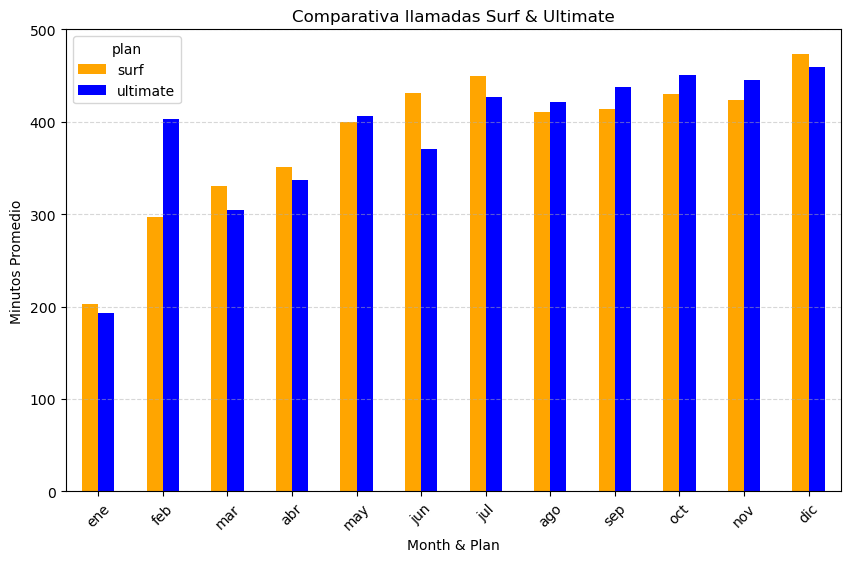

In [43]:
print(calls_per_month.describe())

max_idx= calls_per_month.idxmax()
max_value = calls_per_month.max()

months = {0:'ene',1:'feb',2:'mar',3:'abr',4:'may',5:'jun',6:'jul',7:'ago',8:'sep',9:'oct',10:'nov',11:'dic'}

calls_graph = calls_per_month.plot(kind='bar',
                                        xlabel='Month & Plan', ylabel='Minutos Promedio'
                                        ,color=['orange','blue'], rot=45,
                                        legend=True,
                                        title='Comparativa llamadas Surf & Ultimate',
                                        figsize=(10,6),
                                        ylim=(0,500)
                                        )
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(list(months.keys()),list(months.values()))

plt.show()


Se observa un patrón bastante similar entre los dos planes a lo largo del año. Aunque el plan `ultimate` muestra picos ligeramente más altos en algunos meses, ambos tienen una tendencia clara a incrementar el consumo conforme pasa el tiempo y se acercan las fechas navideñas.

Picos estacionales:

Diciembre: Es, sin duda, el mes con mayor consumo, lo cual está directamente relacionado con las celebraciones de fin de año.

Febrero: También notamos un repunte importante. Es muy probable que se deba a la influencia del 14 de febrero (San Valentín), fecha en la que aumenta el uso de llamadas y mensajes.


# Observaciones:


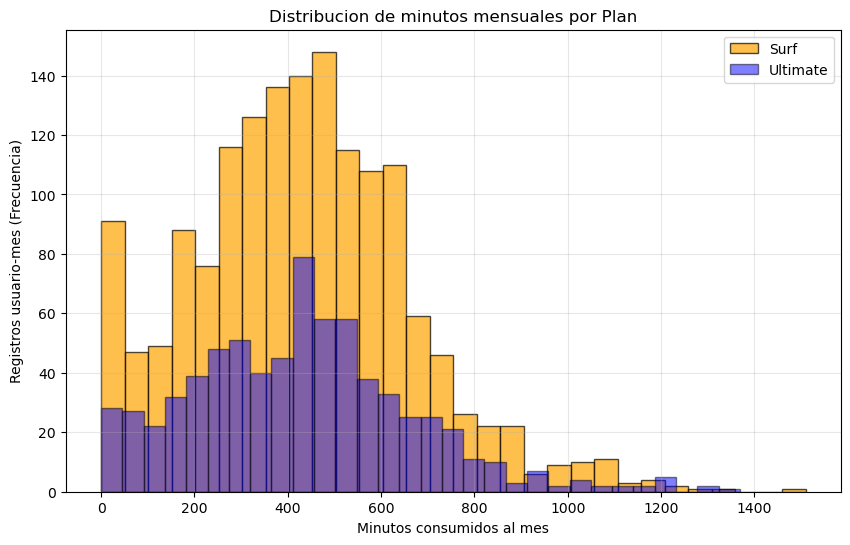


El número total de registros es: 2293
El número total de registros del plan 'surf' es: 1573, lo que equivale a un: 69 %
El número total de registros del plan 'ultimate' es: 720 lo que equivale a un: 31 %


In [44]:
# Compara el número de minutos mensuales que necesitan los usuarios de cada plan. Traza un histograma.



surf_minutes = final_meg_merged[final_meg_merged['plan']=='surf']['minutes_spent']
ultimate_minutes = final_meg_merged[final_meg_merged['plan']=='ultimate']['minutes_spent']

users_total = len(final_meg_merged)
surf_users = len(surf_minutes)
ultimate_users = len(ultimate_minutes)

plt.figure(figsize=(10,6))
plt.hist(surf_minutes, bins=30, alpha=0.7, label='Surf', color='orange', edgecolor='black')
plt.hist(ultimate_minutes, bins=30, alpha=0.5, label='Ultimate', color='blue',edgecolor='black')

plt.legend(loc='upper right')
plt.xlabel('Minutos consumidos al mes')
plt.ylabel('Registros usuario-mes (Frecuencia)')
plt.title('Distribucion de minutos mensuales por Plan')
plt.grid(True, alpha=0.3)
plt.show()

print()
print(f"El número total de registros es: {users_total}")
print(f"El número total de registros del plan 'surf' es: {surf_users}, lo que equivale a un: {((surf_users/users_total)*100):.0f} %")
print(f"El número total de registros del plan 'ultimate' es: {ultimate_users} lo que equivale a un: {((ultimate_users/users_total)*100):.0f} %")

Al observar la distribución, parece seguir una tendencia normal, aunque con un sesgo hacia la derecha (sesgo positivo). Esto significa que, aunque la mayoría de los datos se concentran alrededor de la media, existen algunos valores atípicos o usuarios con consumos significativamente más altos que desplazan la curva.

Observaciones:
La mayor parte de los usuarios mantienen un gasto estable cercano al promedio, lo cual es típico en este tipo de servicios donde la renta básica fija marca el comportamiento principal de la mayoría del grupo.

In [45]:
# Calcula la media y la varianza de la duración mensual de llamadas.

df_surf = final_meg_merged[final_meg_merged['plan'] == 'surf']
df_ultimate = final_meg_merged[final_meg_merged['plan'] == 'ultimate']

surf_mean = df_surf['minutes_spent'].mean()
ultimate_mean = df_ultimate['minutes_spent'].mean()

var_surf = df_surf['minutes_spent'].var()
var_ultimate = df_ultimate['minutes_spent'].var()

surf_std = df_surf['minutes_spent'].std()
ultimate_std = df_ultimate['minutes_spent'].std()

print(f"Plan Surf - Media: {surf_mean:.2f}, Varianza: {var_surf:.2f}, Desviación estndar: {surf_std:.2f}")
print(f"Plan Ultimate - Media: {ultimate_mean:.2f}, Varianza: {var_ultimate:.2f}, Desviación estndar: {ultimate_std:.2f}")
print()
print("Plan Surf:")
print(f"Mínimo: {df_surf['minutes_spent'].min()}")
print(f"Máximo: {df_surf['minutes_spent'].max()}")
print("\nPlan Ultimate:")
print(f"Mínimo: {df_ultimate['minutes_spent'].min()}")
print(f"Máximo: {df_ultimate['minutes_spent'].max()}")

Plan Surf - Media: 428.75, Varianza: 54968.28, Desviación estndar: 234.45
Plan Ultimate - Media: 430.45, Varianza: 57844.46, Desviación estndar: 240.51

Plan Surf:
Mínimo: 0.0
Máximo: 1510.0

Plan Ultimate:
Mínimo: 0.0
Máximo: 1369.0


Los resúmenes y gráficos permiten comparar el centro y la dispersión del consumo. La similitud visual no demuestra normalidad ni igualdad de distribuciones.

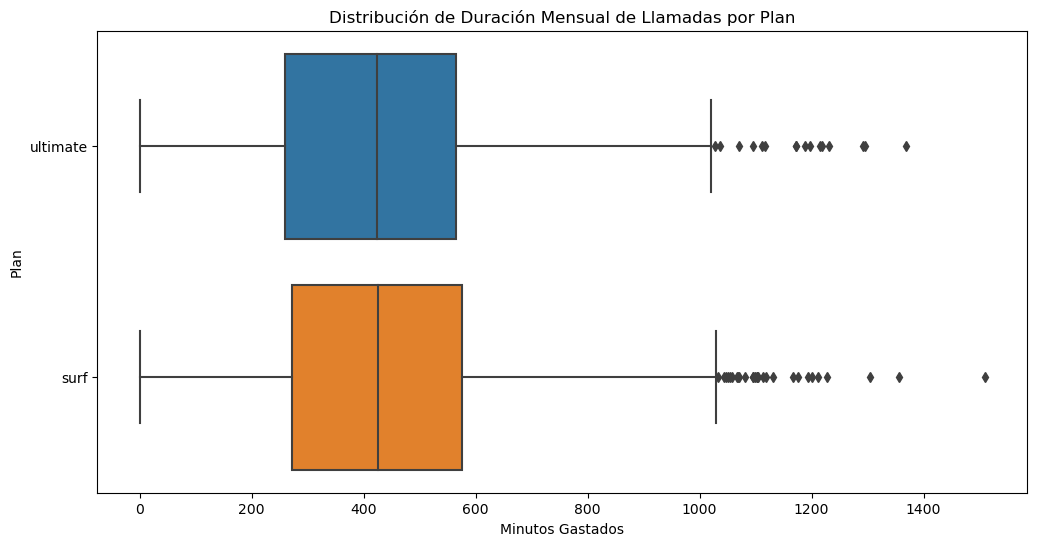

In [46]:
# Traza un diagrama de caja para visualizar la distribución de la duración mensual de llamadas

plt.figure(figsize=(12,6))
sns.boxplot(data=final_meg_merged, y='plan', x='minutes_spent')
plt.title('Distribución de Duración Mensual de Llamadas por Plan')
plt.ylabel('Plan')
plt.xlabel('Minutos Gastados')
plt.show()

El diagrama de caja permite comparar la dispersión del consumo mensual entre ambos planes.


Conclusiones:

Tras analizar el comportamiento de los usuarios, podemos destacar los siguientes puntos:

Patrones de consumo: Los usuarios de ambos planes muestran un comportamiento muy similar en cuanto a llamadas, con incrementos notables conforme se acercan las fechas festivas o periodos vacacionales.

Comportamiento del Plan Surf: Aunque el plan surf tiene un mayor volumen de registros, observamos una cantidad considerable de valores atípicos (outliers). Esto indica que hay un segmento de usuarios que supera ampliamente los límites incluidos en su plan.

Impacto en los ingresos: Esta tendencia es positiva para la compañía, ya que confirma que, incluso en el plan más económico, existe un margen de ingresos extra derivado de los excedentes en el consumo de los usuarios.

### Mensajes

In [47]:
# Comprara el número de mensajes que tienden a enviar cada mes los usuarios de cada plan

user_msg_per_month = msg_per_month.merge(users[['user_id','plan']],on='user_id',how='left')

display(user_msg_per_month.head(2))

user_msg_plan = user_msg_per_month.groupby(['month','plan'])['msg_count'].mean().unstack()


display(user_msg_plan.head(5))
print(user_msg_plan.describe())


,user_id,month,msg_count,plan
0,1000,12,11,ultimate
1,1001,8,30,surf


plan,surf,ultimate
month,,
1,21.000000,20.666667
2,21.600000,25.166667
3,21.937500,34.714286
4,24.166667,28.937500
5,33.017857,44.333333


plan        surf   ultimate
count  12.000000  12.000000
mean   33.309767  39.472325
std     9.179563  10.327408
min    21.000000  20.666667
25%    23.609375  33.270089
50%    34.780747  42.773050
75%    39.780658  47.133632
max    48.326772  53.936508


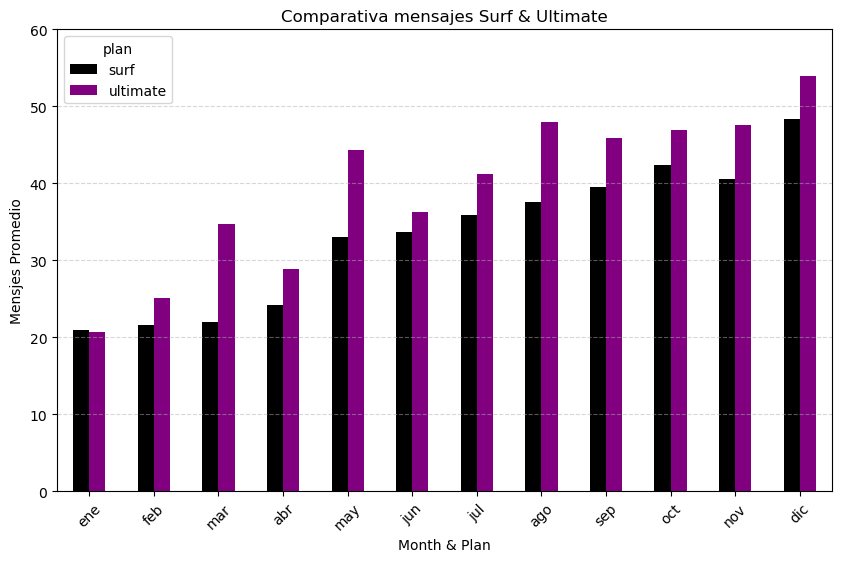

In [48]:
# Compara la cantidad de tráfico de mensjes consumidos por usuarios por plan

msg_graph_2 = user_msg_plan.plot(kind='bar',
                                        xlabel='Month & Plan', ylabel='Mensjes Promedio'
                                        ,color=['black','purple'], rot=45,
                                        legend=True,
                                        title='Comparativa mensajes Surf & Ultimate',
                                        figsize=(10,6),
                                        ylim=(0,60)
                                        )
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(list(months.keys()),list(months.values()))

plt.show()


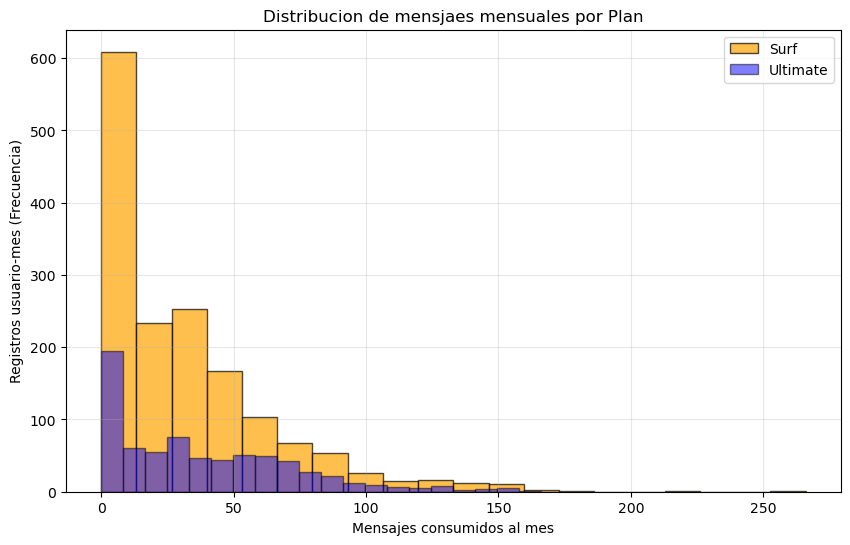


El número total de registros es: 2293
El número total de registros del plan 'surf' es: 1573, lo que equivale a un: 69 %
El número total de registros del plan 'ultimate' es: 720 lo que equivale a un: 31 %


In [49]:


surf_msg = final_meg_merged[final_meg_merged['plan']=='surf']['msg_count']
ultimate_msg = final_meg_merged[final_meg_merged['plan']=='ultimate']['msg_count']

plt.figure(figsize=(10,6))
plt.hist(surf_msg, bins=20, alpha=0.7, label='Surf', color='orange', edgecolor='black')
plt.hist(ultimate_msg, bins=20, alpha=0.5, label='Ultimate', color='blue',edgecolor='black')

plt.legend(loc='upper right')
plt.xlabel('Mensajes consumidos al mes')
plt.ylabel('Registros usuario-mes (Frecuencia)')
plt.title('Distribucion de mensjaes mensuales por Plan')
plt.grid(True, alpha=0.3)
plt.show()

print()
print(f"El número total de registros es: {users_total}")
print(f"El número total de registros del plan 'surf' es: {surf_users}, lo que equivale a un: {((surf_users/users_total)*100):.0f} %")
print(f"El número total de registros del plan 'ultimate' es: {ultimate_users} lo que equivale a un: {((ultimate_users/users_total)*100):.0f} %")


In [50]:
surf_msg_mean = df_surf['msg_count'].mean()
ultimate_msg_mean = df_ultimate['msg_count'].mean()

surf_msg_var = df_surf['msg_count'].var()
ultimate_msg_var = df_ultimate['msg_count'].var()

surf_msg_std = df_surf['msg_count'].std()
ultimate_msg_std = df_ultimate['msg_count'].std()

print(f"Plan Surf - Media: {surf_msg_mean:.2f}, Varianza: {surf_msg_var:.2f}, Desviación estndar: {surf_msg_std:.2f}")
print(f"Plan Ultimate - Media: {ultimate_msg_mean:.2f}, Varianza: {ultimate_msg_var:.2f}, Desviación estndar: {ultimate_msg_std:.2f}")
print()
print("Plan Surf:")
print(f"Mínimo: {df_surf['msg_count'].min()}")
print(f"Máximo: {df_surf['msg_count'].max()}")
print("\nPlan Ultimate:")
print(f"Mínimo: {df_ultimate['msg_count'].min()}")
print(f"Máximo: {df_ultimate['msg_count'].max()}")

Plan Surf - Media: 31.16, Varianza: 1126.72, Desviación estndar: 33.57
Plan Ultimate - Media: 37.55, Varianza: 1208.76, Desviación estndar: 34.77

Plan Surf:
Mínimo: 0.0
Máximo: 266.0

Plan Ultimate:
Mínimo: 0.0
Máximo: 166.0


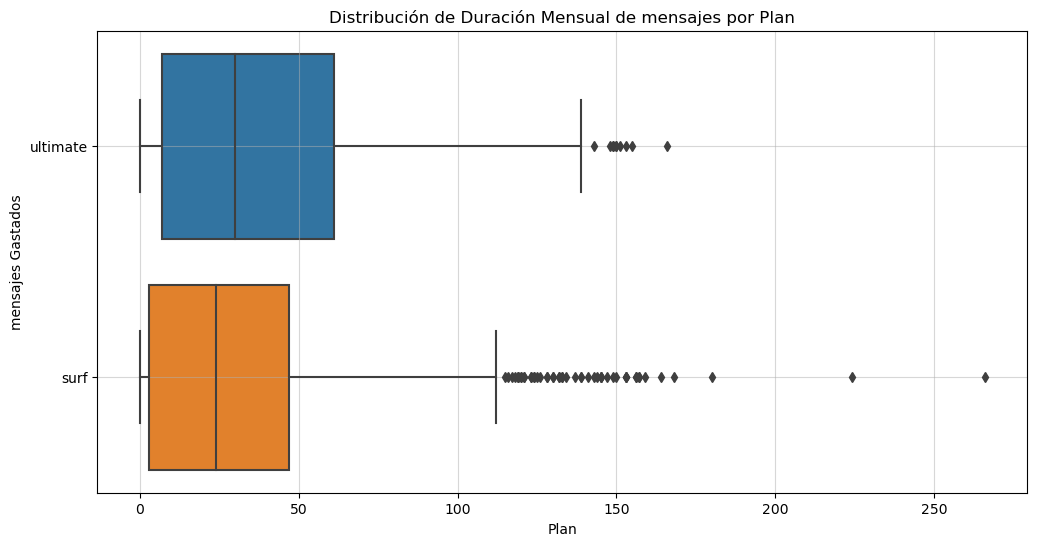

In [51]:
plt.figure(figsize=(12,6))
sns.boxplot(data=final_meg_merged, y='plan', x='msg_count')
plt.title('Distribución de Duración Mensual de mensajes por Plan')
plt.grid(True,alpha=0.5)
plt.xlabel('Plan')
plt.ylabel('mensajes Gastados')
plt.show()


Al revisar el uso de mensajes, notamos que los patrones a lo largo del año son muy similares en ambos planes. Sin embargo, el plan ultimate destaca ligeramente con un consumo más alto. Esto sugiere que los usuarios del plan surf prefieren otras funciones de su plan, como las llamadas, donde registran un uso más elevado que los del plan ultimate.

Observaciones clave:

Distribución: En este caso, encontramos una distribución con sesgo positivo (hacia la derecha).

Similitud estadística: Al igual que en el análisis anterior, la media y la varianza entre planes son muy próximas, lo que confirma una tendencia de comportamiento similar.

Valores atípicos (outliers): Es importante notar que, aunque ambos planes presentan valores atípicos, estos son mucho más frecuentes en el plan surf. Esto indica que, mientras la mayoría no usa los mensajes, hay un grupo reducido de usuarios que los utiliza de manera muy constante.

Uso marginal: Observamos una alta concentración de valores en 0. Esto indica que el servicio de mensajes no es una prioridad para la mayoría, independientemente del plan contratado; parece ser un servicio con baja relevancia frente a otras formas de comunicación digital.

### Internet

In [52]:

display(final_meg_merged.head(2))

int_per_month = final_meg_merged.groupby(['month','plan'])['gb_used'].mean().unstack()

print(int_per_month.describe())

,user_id,month,calls_made,minutes_spent,msg_count,mb_total,gb_used,plan,city,state,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,gb_per_month,usd_per_mb,total_revenue
0,1000,12,16.0,124.0,11.0,1901.47,2.0,ultimate,"Atlanta-Sandy Springs-Roswell, GA MSA",GA,1000,30720,3000,70,7,0.01,0.01,30,0.006836,70.0
1,1001,8,27.0,182.0,30.0,6919.15,7.0,surf,"Seattle-Tacoma-Bellevue, WA MSA",WA,50,15360,500,20,10,0.03,0.03,15,0.009766,20.0


plan        surf   ultimate
count  12.000000  12.000000
mean   14.594808  16.346165
std     3.628348   2.991152
min     5.000000   7.250000
25%    13.229469  16.451977
50%    15.957816  17.064869
75%    16.877704  17.749003
max    18.238994  18.416667


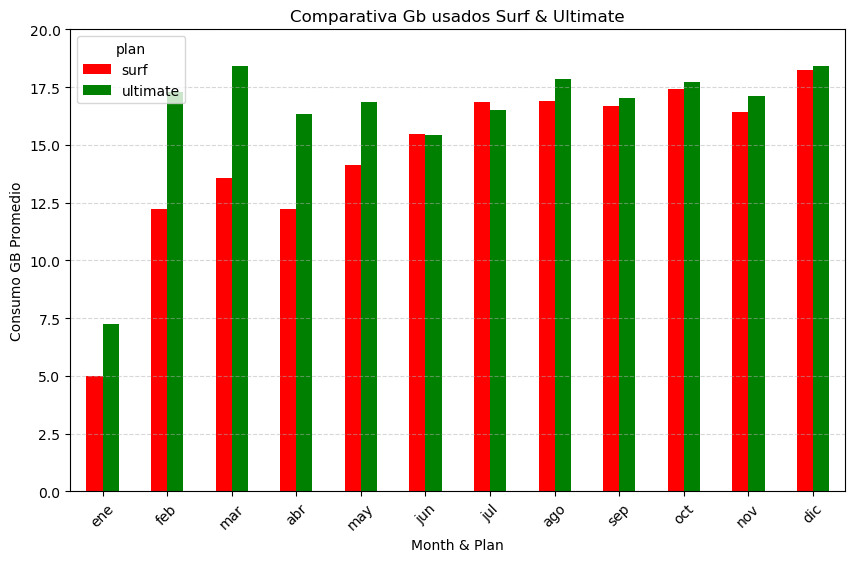

In [53]:
int_graph = int_per_month.plot(kind='bar',
                                        xlabel='Month & Plan', ylabel='Consumo GB Promedio'
                                        ,color=['red','green'], rot=45,
                                        legend=True,
                                        title='Comparativa Gb usados Surf & Ultimate',
                                        figsize=(10,6),
                                        ylim=(0,20)
                                        )
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(list(months.keys()),list(months.values()))

plt.show()

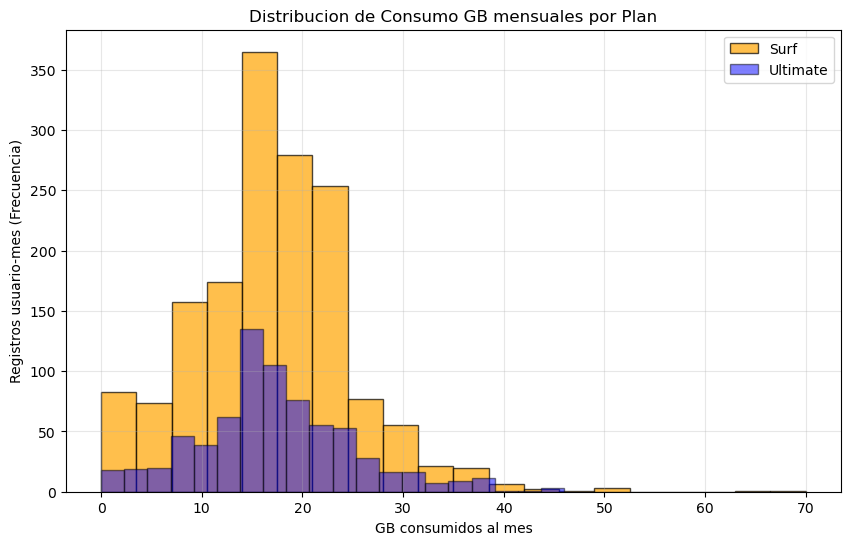


El número total de registros es: 2293
El número total de registros del plan 'surf' es: 1573, lo que equivale a un: 69 %
El número total de registros del plan 'ultimate' es: 720 lo que equivale a un: 31 %


In [54]:
surf_int = final_meg_merged[final_meg_merged['plan']=='surf']['gb_used']
ultimate_int = final_meg_merged[final_meg_merged['plan']=='ultimate']['gb_used']

plt.figure(figsize=(10,6))
plt.hist(surf_int, bins=20, alpha=0.7, label='Surf', color='orange', edgecolor='black')
plt.hist(ultimate_int, bins=20, alpha=0.5, label='Ultimate', color='blue',edgecolor='black')

plt.legend(loc='upper right')
plt.xlabel('GB consumidos al mes')
plt.ylabel('Registros usuario-mes (Frecuencia)')
plt.title('Distribucion de Consumo GB mensuales por Plan')
plt.grid(True, alpha=0.3)
plt.show()

print()
print(f"El número total de registros es: {users_total}")
print(f"El número total de registros del plan 'surf' es: {surf_users}, lo que equivale a un: {((surf_users/users_total)*100):.0f} %")
print(f"El número total de registros del plan 'ultimate' es: {ultimate_users} lo que equivale a un: {((ultimate_users/users_total)*100):.0f} %")

In [55]:
surf_int_mean = df_surf['gb_used'].mean()
ultimate_int_mean = df_ultimate['gb_used'].mean()

surf_int_var = df_surf['gb_used'].var()
ultimate_int_var = df_ultimate['gb_used'].var()

surf_int_std = df_surf['gb_used'].std()
ultimate_int_std = df_ultimate['gb_used'].std()

print(f"Plan Surf - Media: {surf_int_mean:.2f}, Varianza: {surf_int_var:.2f}, Desviación estndar: {surf_int_std:.2f}")
print(f"Plan Ultimate - Media: {ultimate_int_mean:.2f}, Varianza: {ultimate_int_var:.2f}, Desviación estndar: {ultimate_int_std:.2f}")
print()
print("Plan Surf:")
print(f"Mínimo: {df_surf['gb_used'].min()}")
print(f"Máximo: {df_surf['gb_used'].max()}")
print("\nPlan Ultimate:")
print(f"Mínimo: {df_ultimate['gb_used'].min()}")
print(f"Máximo: {df_ultimate['gb_used'].max()}")

Plan Surf - Media: 16.67, Varianza: 61.58, Desviación estndar: 7.85
Plan Ultimate - Media: 17.31, Varianza: 58.83, Desviación estndar: 7.67

Plan Surf:
Mínimo: 0.0
Máximo: 70.0

Plan Ultimate:
Mínimo: 0.0
Máximo: 46.0


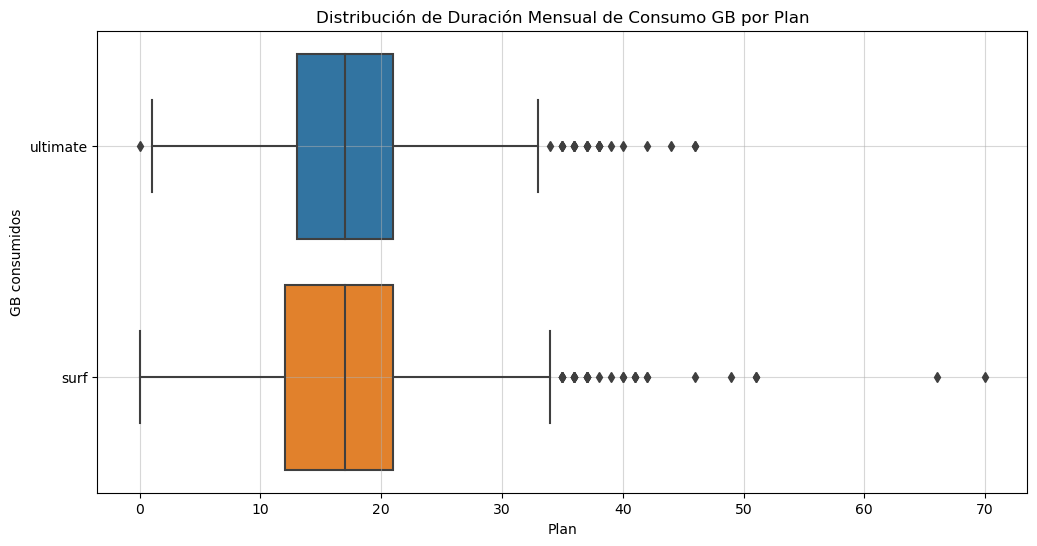

In [56]:
plt.figure(figsize=(12,6))
sns.boxplot(data=final_meg_merged, y='plan', x='gb_used')
plt.title('Distribución de Duración Mensual de Consumo GB por Plan')
plt.grid(True,alpha=0.5)
plt.xlabel('Plan')
plt.ylabel('GB consumidos')
plt.show()


Al analizar el consumo mensual y la distribución de los datos, observamos que, aunque existen diferencias en los límites de cada plan, el comportamiento general entre ambos no varía de forma drástica.

Comportamiento por plan:

Plan Ultimate: En general, los usuarios se mantienen dentro del límite de datos contratado. Aunque existen algunos valores atípicos (outliers), la mayoría de los usuarios no llega a agotar su cupo mensual.

Plan Surf: Aquí la dinámica es distinta. Muchos usuarios requieren más datos de los que incluye el plan, excediendo su límite con frecuencia. Al igual que en el caso anterior, encontramos valores atípicos que superan considerablemente el rango esperado, lo que sugiere un grupo de usuarios con un consumo intensivo.

Conclusiones:

Mientras que los usuarios del plan ultimate suelen estar bajo su límite, los del plan surf tienden a alcanzarlo y superarlo, especialmente durante la segunda mitad del año y en fechas festivas.

A pesar de que el plan ultimate registra un consumo promedio de datos mayor mes a mes, el plan surf destaca por ser el que genera más excedentes, lo cual refuerza la importancia de este plan como fuente de ingresos adicionales.



## Ingreso

In [57]:
display(final_meg_merged.head(2))

revenue_df = final_meg_merged.copy()
cols_to_bill = ['minutes_spent', 'msg_count', 'gb_used']
revenue_df[cols_to_bill] = revenue_df[cols_to_bill].fillna(0)

income_per_month = revenue_df.groupby(['month','plan'])['total_revenue'].mean().unstack()

print(income_per_month.describe())

,user_id,month,calls_made,minutes_spent,msg_count,mb_total,gb_used,plan,city,state,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,gb_per_month,usd_per_mb,total_revenue
0,1000,12,16.0,124.0,11.0,1901.47,2.0,ultimate,"Atlanta-Sandy Springs-Roswell, GA MSA",GA,1000,30720,3000,70,7,0.01,0.01,30,0.006836,70.0
1,1001,8,27.0,182.0,30.0,6919.15,7.0,surf,"Seattle-Tacoma-Bellevue, WA MSA",WA,50,15360,500,20,10,0.03,0.03,15,0.009766,20.0


plan        surf   ultimate
count  12.000000  12.000000
mean   51.401025  72.011068
std    14.698256   1.364068
min    20.000000  70.000000
25%    44.633628  71.409758
50%    53.640282  71.966594
75%    62.988330  72.894366
max    70.557044  74.666667


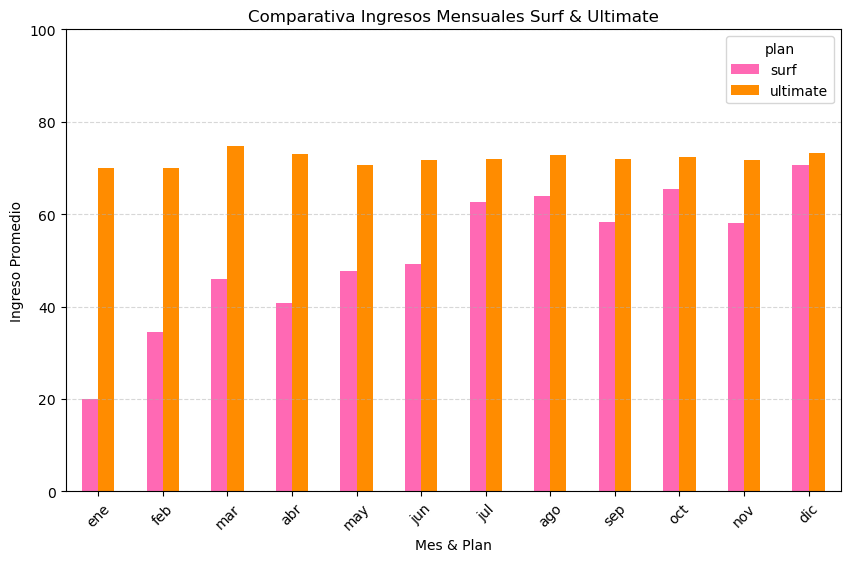

In [58]:
income_graph = income_per_month.plot(kind='bar',
                                        xlabel='Mes & Plan', ylabel='Ingreso Promedio'
                                        ,color=['hotpink','darkorange'], rot=45,
                                        legend=True,
                                        title='Comparativa Ingresos Mensuales Surf & Ultimate',
                                        figsize=(10,6),
                                        ylim=(0,100)
                                        )
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(list(months.keys()),list(months.values()))

plt.show()

In [59]:
surf_income = final_meg_merged[final_meg_merged['plan']=='surf']['total_revenue']
ultimate_income = final_meg_merged[final_meg_merged['plan']=='ultimate']['total_revenue']

max_surf = surf_income.max()
max_ultimate = ultimate_income.max()

print(f"Máximo Surf: ${max_surf:.2f}")
print(f"Máximo Ultimate: ${max_ultimate:.2f}")

Máximo Surf: $590.37
Máximo Ultimate: $182.00


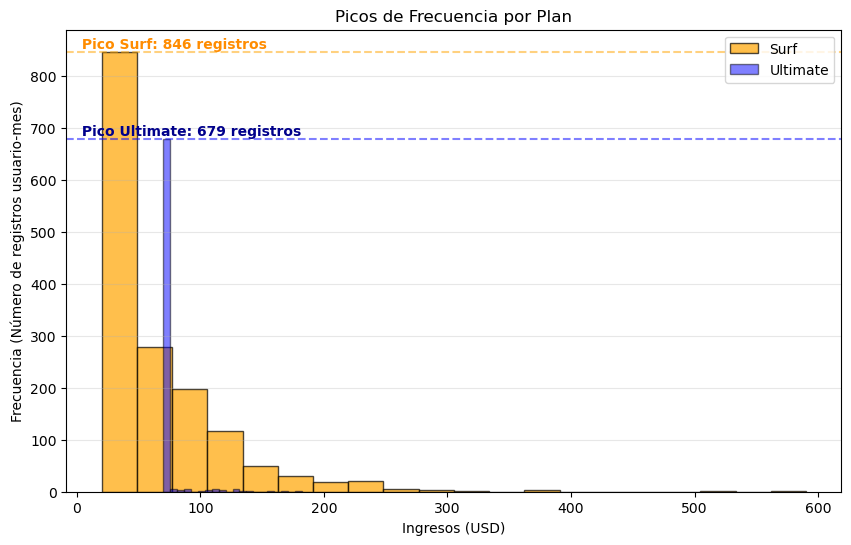


°El número total de registros es: 2293
°El número total de registros del plan 'surf' es: 1573, lo que equivale a un: 69 %
°El número total de registros del plan 'ultimate' es: 720 lo que equivale a un: 31 %

- De un total de 1573 registros Surf, 
846 Usuarios se mantien dentro de su limite de consumo. 
Lo que representa un 53.78% del ingreso total del plan Surf. 
Alrededor de $17020.00 USD

- De un Ingreso Total de $ 95491.18 USD con el Plan Surf

- De un total de 720 registros Ultimate, 
679 Usuarios se mantien dentro de su limite de consumo. 
Lo que representa un 94.31% del ingreso total del plan Ultimate. 
Alrededor de $47530.00 USD

- De un Ingreso Total de $ 52066.00 USD con el Plan Ultimate


In [60]:
surf_income = final_meg_merged[final_meg_merged['plan']=='surf']['total_revenue']
ultimate_income = final_meg_merged[final_meg_merged['plan']=='ultimate']['total_revenue']

plt.figure(figsize=(10,6))

# Guardamos el resultado del histograma en variables
# 'n' contiene las alturas (frecuencias) de cada barra
n_surf, bins_surf, _ = plt.hist(surf_income, bins=20, alpha=0.7, label='Surf', color='orange', edgecolor='black')
n_ultimate, bins_ultimate, _ = plt.hist(ultimate_income, bins=20, alpha=0.5, label='Ultimate', color='blue', edgecolor='black')

# Encontramos el valor máximo de las alturas
max_freq_surf = n_surf.max()
max_freq_ultimate = n_ultimate.max()

# Dibujamos una línea horizontal y colocamos un texto en el pico
plt.axhline(max_freq_surf, color='orange', linestyle='--', alpha=0.5)
plt.text(0, max_freq_surf, f' Pico Surf: {int(max_freq_surf)} registros', color='darkorange', fontweight='bold', va='bottom')

plt.axhline(max_freq_ultimate, color='blue', linestyle='--', alpha=0.5)
plt.text(0, max_freq_ultimate, f' Pico Ultimate: {int(max_freq_ultimate)} registros', color='darkblue', fontweight='bold', va='bottom')

plt.legend(loc='upper right')
plt.xlabel('Ingresos (USD)')
plt.ylabel('Frecuencia (Número de registros usuario-mes)')
plt.title('Picos de Frecuencia por Plan')
plt.grid(axis='y', alpha=0.3)
plt.show()

print()
print(f"°El número total de registros es: {users_total}")
print(f"°El número total de registros del plan 'surf' es: {surf_users}, lo que equivale a un: {((surf_users/users_total)*100):.0f} %")
print(f"°El número total de registros del plan 'ultimate' es: {ultimate_users} lo que equivale a un: {((ultimate_users/users_total)*100):.0f} %")
print(f"\n- De un total de {surf_users} registros Surf, \n{max_freq_surf.astype('int')} Usuarios se mantien dentro de su limite de consumo. \nLo que representa un {((max_freq_surf/surf_users)*100):.2f}% del ingreso total del plan Surf. \nAlrededor de ${(20*851):.2f} USD")
print(f"\n- De un Ingreso Total de $ {final_meg_merged[final_meg_merged['plan'] == 'surf']['total_revenue'].sum():.2f} USD con el Plan Surf")
print(f"\n- De un total de {ultimate_users} registros Ultimate, \n{max_freq_ultimate.astype('int')} Usuarios se mantien dentro de su limite de consumo. \nLo que representa un {((max_freq_ultimate/ultimate_users)*100):.2f}% del ingreso total del plan Ultimate. \nAlrededor de ${(70*679):.2f} USD")
print(f"\n- De un Ingreso Total de $ {final_meg_merged[final_meg_merged['plan'] == 'ultimate']['total_revenue'].sum():.2f} USD con el Plan Ultimate")

In [61]:
surf_income_mean = df_surf['total_revenue'].mean()
ultimate_income_mean = df_ultimate['total_revenue'].mean()

surf_income_var = df_surf['total_revenue'].var()
ultimate_income_var = df_ultimate['total_revenue'].var()

surf_income_std = df_surf['total_revenue'].std()
ultimate_income_std = df_ultimate['total_revenue'].std()

print(f"Plan Surf - Media: {surf_income_mean:.2f}, Varianza: {surf_income_var:.2f}, Desviación estndar: {surf_income_std:.2f}")
print(f"Plan Ultimate - Media: {ultimate_income_mean:.2f}, Varianza: {ultimate_income_var:.2f}, Desviación estndar: {ultimate_income_std:.2f}")
print()
print("Plan Surf:")
print(f"Mínimo: {df_surf['total_revenue'].min()}")
print(f"Máximo: {df_surf['total_revenue'].max()}")
print("\nPlan Ultimate:")
print(f"Mínimo: {df_ultimate['total_revenue'].min()}")
print(f"Máximo: {df_ultimate['total_revenue'].max()}")

Plan Surf - Media: 60.71, Varianza: 3067.84, Desviación estndar: 55.39
Plan Ultimate - Media: 72.31, Varianza: 129.85, Desviación estndar: 11.40

Plan Surf:
Mínimo: 20.0
Máximo: 590.37

Plan Ultimate:
Mínimo: 70.0
Máximo: 182.0


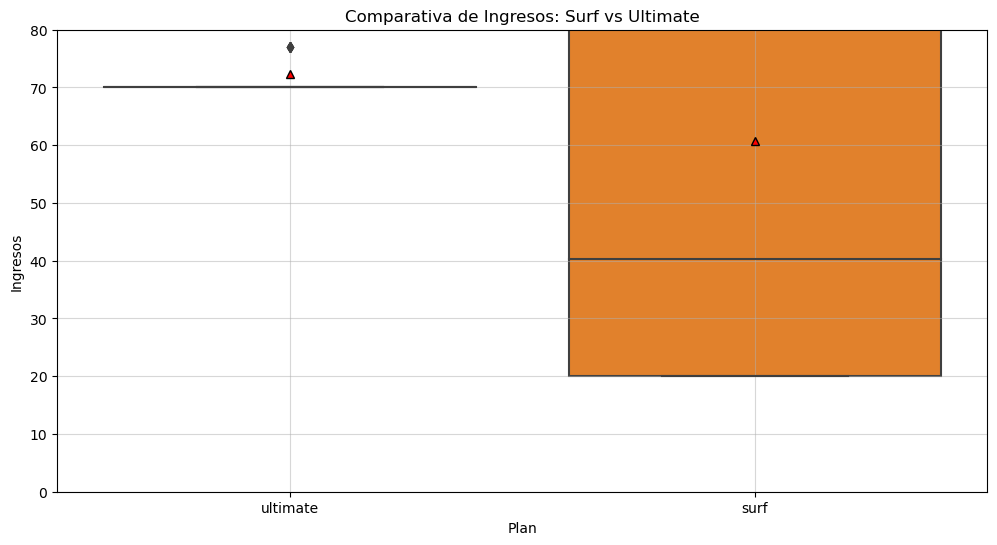

In [62]:

plt.figure(figsize=(12,6))
sns.boxplot(data=final_meg_merged, x='plan', y='total_revenue', showmeans=True, meanprops={"markerfacecolor":"red", "markeredgecolor":"black"})
plt.title('Comparativa de Ingresos: Surf vs Ultimate')
plt.grid(True,alpha=0.5)
plt.ylim(0,80)
plt.xlabel('Plan')
plt.ylabel('Ingresos')
plt.show()


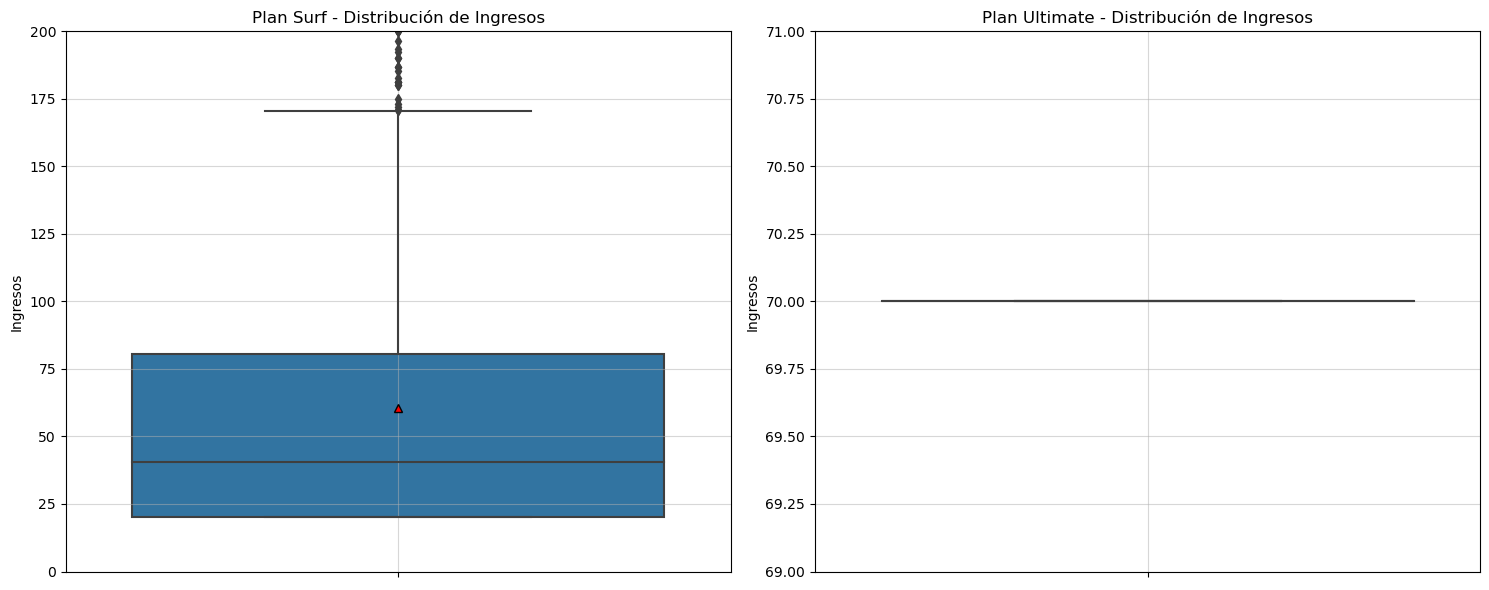

In [63]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

surf_data = final_meg_merged[final_meg_merged['plan'] == 'surf']
ultimate_data = final_meg_merged[final_meg_merged['plan'] == 'ultimate']

# Gráfico 1: Plan Surf
sns.boxplot(data=surf_data, y='total_revenue', ax=ax1, showmeans=True, 
            meanprops={"markerfacecolor":"red", "markeredgecolor":"black"})
ax1.set_title('Plan Surf - Distribución de Ingresos')
ax1.set_ylabel('Ingresos')
ax1.grid(True, alpha=0.5)
ax1.set_ylim(0, 200)

# Gráfico 2: Plan Ultimate
sns.boxplot(data=ultimate_data, y='total_revenue', ax=ax2, showmeans=True, 
            meanprops={"markerfacecolor":"red", "markeredgecolor":"black"})
ax2.set_title('Plan Ultimate - Distribución de Ingresos')
ax2.set_ylabel('Ingresos')
ax2.grid(True, alpha=0.5)
ax2.set_ylim(69,71)

plt.tight_layout()
plt.show()

**Cálculo de ingresos mensuales por usuario**

Para determinar el ingreso total, calculamos los costos excedentes en llamadas, mensajes y tráfico de internet, sumándolos al costo base de cada plan. Utilizamos la función `np.maximum(0, diferencia)` para garantizar que, si el consumo está dentro del límite, el costo adicional sea `0`.

**Cálculo de excedentes:**

- Minutos: Calculamos la diferencia entre los minutos consumidos y los incluidos, multiplicando el resultado positivo por `usd_per_minute`.

- Mensajes: Obtenemos el costo extra multiplicando el exceso de mensajes por `usd_per_message`.

- Datos (GB): Calculamos el costo por GB excedente multiplicando por `usd_per_gb`.

- Ingreso total (`total_revenue`):
Consolidamos el costo mensual base del plan más los costos variables calculados previamente.

Codigo:
`final_meg_merged['total_revenue'] = (final_meg_merged['usd_monthly_pay'] + mins_cost + msg_cost + gb_cost)`

Validación de resultados:

Finalmente, extraemos un resumen con las columnas user_id, month, plan y total_revenue. Ejecutamos `isna().sum()` para confirmar la integridad de los datos; la ausencia de valores nulos es el indicador clave de que el cálculo y la consolidación de unidades se realizaron exitosamente.

In [64]:
# Sumamos el total de cada columna de costo que calculamos antes
total_mins_usd = mins_cost.sum()
total_msgs_usd = msg_cost.sum()
total_gb_usd = gb_cost.sum()
total_base_usd = final_meg_merged['usd_monthly_pay'].sum()

print("--- DESGLOSE DE INGRESOS TOTALES (MUESTRA COMPLETA) ---")
print(f"Ingresos por rentas básicas:  ${total_base_usd:,.2f}")
print(f"Ingresos por exceso de GB:    ${total_gb_usd:,.2f}")
print(f"Ingresos por exceso de Min:    ${total_mins_usd:,.2f}")
print(f"Ingresos por exceso de SMS:    ${total_msgs_usd:,.2f}")
print("-" * 40)
print(f"INGRESO TOTAL FACTURADO:           ${(total_base_usd + total_gb_usd + total_mins_usd + total_msgs_usd):,.2f}")


--- DESGLOSE DE INGRESOS TOTALES (MUESTRA COMPLETA) ---
Ingresos por rentas básicas:  $81,860.00
Ingresos por exceso de GB:    $62,466.00
Ingresos por exceso de Min:    $2,900.25
Ingresos por exceso de SMS:    $330.93
----------------------------------------
INGRESO TOTAL FACTURADO:           $147,557.18


## Comparación de ingresos

Ultimate tiene una tarifa base mayor y sus ingresos mensuales varían menos. Surf tiene una tarifa base menor y más variación por excedentes. Para distinguir ambas fuentes, calculé por separado renta básica, llamadas, mensajes e internet. Los importes facturados no equivalen a ganancias: el dataset no incluye costos.

## Prueba las hipótesis estadísticas

Comparé las medias con pruebas bilaterales de Welch y significancia de 0.05. Para evitar tratar varios meses del mismo usuario como observaciones independientes, utilicé el ingreso mensual promedio de cada usuario. La comparación describe asociaciones; los planes no fueron asignados aleatoriamente.

In [65]:
alpha = 0.05
user_income = final_meg_merged.groupby(['user_id','plan','state'], as_index=False)['total_revenue'].mean()
surf_user_income = user_income.loc[user_income.plan == 'surf','total_revenue']
ultimate_user_income = user_income.loc[user_income.plan == 'ultimate','total_revenue']
results_income = st.ttest_ind(surf_user_income, ultimate_user_income, equal_var=False)
print('Valor p (promedio mensual por usuario):', results_income.pvalue)
print('Rechazamos la hipótesis nula' if results_income.pvalue < alpha else 'No podemos rechazar la hipótesis nula')


Valor p (promedio mensual por usuario): 5.719435130362412e-08
Rechazamos la hipótesis nula


Utilicé `equal_var=False` para no asumir varianzas iguales entre los grupos.

La decisión estadística se obtiene al comparar el valor p con 0.05. Un valor p pequeño aporta evidencia contra la igualdad de medias bajo los supuestos de la prueba; no mide la probabilidad de que una hipótesis sea cierta.

## ¿El ingreso promedio de los usuarios del área NY-NJ es diferente al de los usuarios de otras regiones.?

Comparé el ingreso mensual promedio por usuario de los estados codificados como `NY-NJ-PA` o `NY` frente al resto. Apliqué una prueba bilateral de Welch con significancia de 0.05.

In [66]:
in_region = user_income.state.isin(['NY-NJ-PA','NY'])
reg_results = st.ttest_ind(user_income.loc[in_region,'total_revenue'],user_income.loc[~in_region,'total_revenue'],equal_var=False)
print('Usuarios por grupo:', int(in_region.sum()), int((~in_region).sum()))
print('Valor p:', reg_results.pvalue)
print('Rechazamos la hipótesis nula' if reg_results.pvalue < alpha else 'No podemos rechazar la hipótesis nula')


Usuarios por grupo: 85 405
Valor p: 0.5630003760570831
No podemos rechazar la hipótesis nula


## Conclusión general

Después de analizar los datos, encontré dos estructuras de ingresos distintas: Ultimate aporta una tarifa base mayor y Surf presenta más variación por excedentes. El consumo de internet merece especial atención al comparar las facturas.

Como siguiente paso, estudiaría un plan intermedio para quienes exceden su paquete de datos con frecuencia. Es una propuesta a evaluar; no una mejora comercial demostrada.

El análisis incluye meses con algún registro de uso y no reconstruye meses completamente inactivos. Las pruebas usan un promedio por usuario; no rechazar una hipótesis no demuestra igualdad entre grupos. La muestra es histórica y no garantiza que el comportamiento se mantenga en otros clientes o períodos.

## Resumen de resultados

Consolidé los principales indicadores y un gráfico para comparar los resultados.

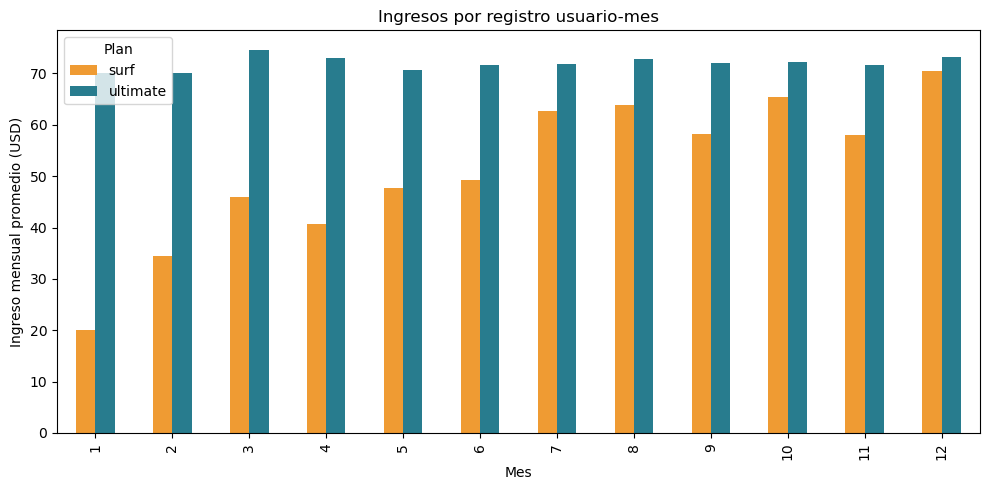

,user_months,users,mean_monthly_revenue,total_revenue
plan,,,,
surf,1573,333,60.706408,95491.18
ultimate,720,157,72.313889,52066.00


In [67]:
from pathlib import Path
import json
OUT = Path.cwd()
(OUT/'reports').mkdir(exist_ok=True); (OUT/'assets').mkdir(exist_ok=True)
by_plan = final_meg_merged.groupby('plan').agg(user_months=('total_revenue','size'),users=('user_id','nunique'),mean_monthly_revenue=('total_revenue','mean'),total_revenue=('total_revenue','sum'))
by_plan.to_csv(OUT/'reports/plan_summary.csv')
metrics = {'users_input':len(users),'users_with_usage':int(final_meg_merged.user_id.nunique()),'user_months':len(final_meg_merged),
 'plan_summary':by_plan.to_dict(orient='index'),'plan_test_pvalue':float(results_income.pvalue),
 'region_test_pvalue':float(reg_results.pvalue),'test_unit':'Ingreso mensual promedio por usuario',
 'significance':0.05,'extra_data_revenue':float(total_gb_usd),'base_revenue':float(total_base_usd),
 'total_revenue':float(final_meg_merged.total_revenue.sum())}
(OUT/'reports/metrics.json').write_text(json.dumps(metrics,ensure_ascii=False,indent=2),encoding='utf-8')
ax=income_per_month.plot(kind='bar',figsize=(10,5),color=['#ef9b33','#287c8e'])
ax.set(xlabel='Mes',ylabel='Ingreso mensual promedio (USD)',title='Ingresos por registro usuario-mes')
ax.legend(title='Plan'); plt.tight_layout(); plt.savefig(OUT/'assets/ingresos_mensuales.png',dpi=140); plt.show()
display(by_plan)
